In [1]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from itertools import product
from scipy.signal import find_peaks
import random
import math
from sklearn.metrics import confusion_matrix, roc_curve, auc, mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import sentiment_analysis as sa

In [2]:
clean_gpu_memory = sa.clean_gpu_memory
check_gpu_memory = sa.check_gpu_memory
reduce_memory_usage = sa.reduce_memory_usage

In [3]:
class StockLSTM(nn.Module):
    """
    A simple LSTM model for stock price prediction.
    """
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(StockLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Define LSTM
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.4)

        # Define fully connected layers after LSTM
        self.fc_layers = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, output_size)
        )

    def forward(self, x):
        # Initial hidden and cell states
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = self.fc_layers(out[:, -1, :])  # Take the last timestep
        return out

In [4]:
def compute_technical_indicators(data):
    """
    Computes various technical indicators such as MACD, RSI, ATR, MFI, Bollinger Bands, etc.
    Returns the modified DataFrame with new columns.
    """
    # Exponential Moving Averages for MACD
    data['EMA_12'] = data['Close'].ewm(span=12, adjust=False).mean()
    data['EMA_26'] = data['Close'].ewm(span=26, adjust=False).mean()
    data['MACD'] = data['EMA_12'] - data['EMA_26']
    data['MACD_Signal'] = data['MACD'].ewm(span=9, adjust=False).mean()
    
    # RSI
    delta = data['Close'].diff()
    gain = delta.where(delta > 0, 0.0)
    loss = -delta.where(delta < 0, 0.0)
    window_length = 14
    avg_gain = gain.rolling(window=window_length, min_periods=window_length).mean()
    avg_loss = loss.rolling(window=window_length, min_periods=window_length).mean()
    rs = avg_gain / avg_loss
    data['RSI'] = 100.0 - (100.0 / (1.0 + rs))
    data['RSI'].fillna(0, inplace=True)

    # ATR
    data['HL'] = data['High'] - data['Low']
    data['HC'] = abs(data['High'] - data['Close'].shift(1))
    data['LC'] = abs(data['Low'] - data['Close'].shift(1))
    data['TR'] = data[['HL', 'HC', 'LC']].max(axis=1)
    atr_window = 14
    data['ATR'] = data['TR'].rolling(window=atr_window, min_periods=atr_window).mean()
    data['ATR'].fillna(0, inplace=True)
    
    # MFI
    data['TP'] = (data['High'] + data['Low'] + data['Close']) / 3
    data['RMF'] = data['TP'] * data['Volume']
    data['PMF'] = np.where(data['Close'] > data['Close'].shift(1), data['RMF'], 0)
    data['NMF'] = np.where(data['Close'] < data['Close'].shift(1), data['RMF'], 0)
    mfi_window = 14
    positive_mf = data['PMF'].rolling(window=mfi_window, min_periods=mfi_window).sum()
    negative_mf = data['NMF'].rolling(window=mfi_window, min_periods=mfi_window).sum()
    money_ratio = positive_mf / negative_mf
    data['MFI'] = 100 - 100 / (1 + money_ratio)
    data['MFI'].fillna(0, inplace=True)
    
    # Bollinger Bands
    bb_window = 20
    bb_std = 2
    data['BB_Middle'] = data['Close'].rolling(window=bb_window, min_periods=bb_window).mean()
    data['BB_Std'] = data['Close'].rolling(window=bb_window, min_periods=bb_window).std()
    data['BB_Upper'] = data['BB_Middle'] + (bb_std * data['BB_Std'])
    data['BB_Lower'] = data['BB_Middle'] - (bb_std * data['BB_Std'])
    data[['BB_Middle','BB_Std','BB_Upper','BB_Lower']] = data[['BB_Middle','BB_Std','BB_Upper','BB_Lower']].fillna(method='bfill')
    
    # Stochastic Oscillator
    so_window = 14
    data['SO_Low'] = data['Low'].rolling(window=so_window, min_periods=so_window).min()
    data['SO_High'] = data['High'].rolling(window=so_window, min_periods=so_window).max()
    data['SO_%K'] = ((data['Close'] - data['SO_Low']) / (data['SO_High'] - data['SO_Low'])) * 100
    data['SO_%D'] = data['SO_%K'].rolling(window=3, min_periods=3).mean()
    data['SO_%K'].fillna(0, inplace=True)
    data['SO_%D'].fillna(0, inplace=True)
    
    # ADX
    data['+DM'] = np.where(
        (data['High'] - data['High'].shift(1)) > (data['Low'].shift(1) - data['Low']), 
        np.maximum(data['High'] - data['High'].shift(1), 0), 0
    )
    data['-DM'] = np.where(
        (data['Low'].shift(1) - data['Low']) > (data['High'] - data['High'].shift(1)), 
        np.maximum(data['Low'].shift(1) - data['Low'], 0), 0
    )
    data['TR_Smoothed'] = data['TR'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['+DM_Smoothed'] = data['+DM'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['-DM_Smoothed'] = data['-DM'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['+DI'] = (data['+DM_Smoothed'] / data['TR_Smoothed']) * 100
    data['-DI'] = (data['-DM_Smoothed'] / data['TR_Smoothed']) * 100
    data['DX'] = (np.abs(data['+DI'] - data['-DI']) / (data['+DI'] + data['-DI'])) * 100
    data['ADX'] = data['DX'].rolling(window=atr_window, min_periods=atr_window).mean()
    data['ADX'].fillna(0, inplace=True)
    
    data['MACD_Histogram'] = data['MACD'] - data['MACD_Signal']
    data['MACD_Histogram'].fillna(0, inplace=True)
    
    # VWAP
    data['Cumulative_TP_Volume'] = (data['Close'] * data['Volume']).cumsum()
    data['Cumulative_Volume'] = data['Volume'].cumsum()
    data['VWAP'] = data['Cumulative_TP_Volume'] / data['Cumulative_Volume']
    data['VWAP'].fillna(0, inplace=True)
    
    # CMF
    cmf_window = 20
    data['MFM'] = ((data['Close'] - data['Low']) - (data['High'] - data['Close'])) / (data['High'] - data['Low'])
    data['MFM'].replace([np.inf, -np.inf], 0, inplace=True)
    data['MFM'].fillna(0, inplace=True)
    data['MFV'] = data['MFM'] * data['Volume']
    data['CMF'] = (data['MFV'].rolling(window=cmf_window, min_periods=cmf_window).sum() /
                   data['Volume'].rolling(window=cmf_window, min_periods=cmf_window).sum())
    data['CMF'].fillna(0, inplace=True)
    
    # Fibonacci Levels
    fib_period = 60
    max_close = data['Close'].rolling(window=fib_period, min_periods=fib_period).max()
    min_close = data['Close'].rolling(window=fib_period, min_periods=fib_period).min()
    data['Fib_23.6'] = max_close - (max_close - min_close) * 0.236
    data['Fib_38.2'] = max_close - (max_close - min_close) * 0.382
    data['Fib_50.0'] = max_close - (max_close - min_close) * 0.5
    data['Fib_61.8'] = max_close - (max_close - min_close) * 0.618
    data['Fib_76.4'] = max_close - (max_close - min_close) * 0.764
    fib_levels = ['Fib_23.6','Fib_38.2','Fib_50.0','Fib_61.8','Fib_76.4']
    for level in fib_levels:
        data[level].fillna(method='bfill', inplace=True)
        data[level].fillna(method='ffill', inplace=True)
        data[level].fillna(0, inplace=True)
    
    # ROC
    roc_window = 12
    data['ROC'] = ((data['Close'] - data['Close'].shift(roc_window)) / data['Close'].shift(roc_window)) * 100
    data['ROC'].fillna(0, inplace=True)
    
    # Basic Parabolic SAR (simplified approach)
    psar_step = 0.02
    psar_max = 0.2
    data['PSAR'] = data['Close']  # Initialize with close
    if len(data) > 1:
        long = True
        af = psar_step
        ep = data['High'].iloc[0]
        psar = data['Low'].iloc[0]
        for i in range(1, len(data)):
            prev_psar = psar
            if long:
                psar = prev_psar + af * (ep - prev_psar)
                psar = min(psar, data['Low'].iloc[i-1],
                           data['Low'].iloc[i-2] if i >= 2 else data['Low'].iloc[i-1])
            else:
                psar = prev_psar + af * (ep - prev_psar)
                psar = max(psar, data['High'].iloc[i-1],
                           data['High'].iloc[i-2] if i >= 2 else data['High'].iloc[i-1])
            
            reverse = False
            if long and data['Low'].iloc[i] < psar:
                long = False
                reverse = True
                psar = ep
                ep = data['Low'].iloc[i]
                af = psar_step
            elif not long and data['High'].iloc[i] > psar:
                long = True
                reverse = True
                psar = ep
                ep = data['High'].iloc[i]
                af = psar_step
            
            if not reverse:
                if long and data['High'].iloc[i] > ep:
                    ep = data['High'].iloc[i]
                    af = min(af + psar_step, psar_max)
                elif not long and data['Low'].iloc[i] < ep:
                    ep = data['Low'].iloc[i]
                    af = min(af + psar_step, psar_max)
            
            data.at[data.index[i], 'PSAR'] = psar
    
    # Remove temporary columns
    temporary_cols = [
        'EMA_12','EMA_26','HL','HC','LC','TP','RMF','PMF','NMF',
        'TR_Smoothed','+DM_Smoothed','-DM_Smoothed','+DM','-DM',
        'SO_Low','SO_High'
    ]
    data.drop(columns=temporary_cols, inplace=True, errors='ignore')
    
    return data

In [5]:
def integrate_sentiment_if_recent(price_data, sentiment_data, cutoff_date_str="2025-04-17"):
    """
    Integrates sentiment data with time-weighted approach:
    - Each sentiment affects 4 days with weights [1.0, 0.6, 0.25, 0.0]
    - Only applies sentiment after the cutoff date
    - Fixed to handle date formatting issues and prevent NaT values
    """
    # Convert cutoff_date_str to datetime if it's a string
    if isinstance(cutoff_date_str, str):
        try:
            cutoff_date = pd.to_datetime(cutoff_date_str)
        except:
            # If conversion fails, use a default (90 days before latest price data)
            if len(price_data) > 0:
                cutoff_date = price_data.index.max() - pd.Timedelta(days=90)
            else:
                cutoff_date = pd.Timestamp.now() - pd.Timedelta(days=90)
    elif isinstance(cutoff_date_str, pd.Timestamp):
        cutoff_date = cutoff_date_str
    else:
        # Default to 90 days before latest price data
        if len(price_data) > 0:
            cutoff_date = price_data.index.max() - pd.Timedelta(days=90)
        else:
            cutoff_date = pd.Timestamp.now() - pd.Timedelta(days=90)
    
    # Check for finbert_composite column
    if 'finbert_composite' not in sentiment_data.columns:
        print("Warning: 'finbert_composite' column not found in sentiment data!")
        print("Creating empty finbert_composite column with zeros.")
        sentiment_data['finbert_composite'] = 0.0
   
    # Create a copy of price_data to avoid modifying the original
    result_data = price_data.copy()
    
    # Ensure the indices are proper datetime format and sorted
    # Handle possible errors in conversion
    try:
        sentiment_data.index = pd.to_datetime(sentiment_data.index, errors='coerce')
        result_data.index = pd.to_datetime(result_data.index, errors='coerce')
        
        # Remove any rows with NaT index values
        sentiment_data = sentiment_data[~sentiment_data.index.isna()]
        result_data = result_data[~result_data.index.isna()]
    except Exception as e:
        print(f"Warning: Issue during datetime conversion: {e}")
        # Fall back to original data if conversion fails
    
    # Sort the indices
    sentiment_data = sentiment_data.sort_index()
    result_data = result_data.sort_index()
    
    # Add sentiment_score and has_sentiment columns to result_data, initialized to 0
    result_data['sentiment_score'] = 0.0
    result_data['has_sentiment'] = 0
    
    # Define the decay weights
    day_weights = [1.0, 0.6, 0.25, 0.0]  # Last weight is 0, but included for clarity
    
    # Extract only the finbert_composite column and convert to a simple dictionary for quick lookups
    if 'finbert_composite' in sentiment_data.columns:
        # Convert index.date to string to avoid issues with date comparisons
        sentiment_dates = [d.date() if isinstance(d, pd.Timestamp) else d for d in sentiment_data.index]
        grouped_sentiment = sentiment_data.groupby(sentiment_dates)['finbert_composite'].mean()
        
        # Generate a date range spanning the entire price data (excluding NaTs)
        all_dates = pd.DatetimeIndex([d for d in result_data.index if isinstance(d, pd.Timestamp)])
        
        # For each date in price data
        for date in all_dates:
            # Skip if date is not a valid timestamp
            if not isinstance(date, pd.Timestamp):
                continue
                
            date_only = date.date()
            
            # For each date, calculate influence from previous days
            total_influence = 0
            has_influence = False
            
            # Look back up to 3 days (the weighting window)
            for days_back in range(4):  # 0, 1, 2, 3 days back
                # Calculate source date
                source_date = (date - pd.Timedelta(days=days_back)).date()
                
                # If this past date has sentiment, apply its weighted influence
                if source_date in grouped_sentiment.index:
                    sentiment_value = grouped_sentiment[source_date]
                    
                    # Apply appropriate weight based on days_back
                    weight = day_weights[days_back]
                    
                    # Skip if weight or sentiment is 0
                    if weight == 0 or sentiment_value == 0:
                        continue
                        
                    # Calculate weighted influence
                    influence = sentiment_value * weight
                    total_influence += influence
                    has_influence = True
            
            # Set the final sentiment score and flag
            if has_influence:
                result_data.at[date, 'sentiment_score'] = total_influence
                result_data.at[date, 'has_sentiment'] = 1
    
    # Report stats
    non_zero_count = (result_data['has_sentiment'] == 1).sum()
    total_count = len(result_data)
    
    return result_data

In [6]:
def prepare_data(data, lookback=60, future_target=1):
    """
    Prepares data for training LSTM:
      - Selects necessary features.
      - Scales data with MinMaxScaler.
      - Creates sequences of length 'lookback'.
      - Creates targets 'future_target' days ahead.
    """
    # First, rename finbert_composite to sentiment_score if it exists
    if 'finbert_composite' in data.columns and 'sentiment_score' not in data.columns:
        data['sentiment_score'] = data['finbert_composite']
        print("Renamed 'finbert_composite' to 'sentiment_score' for consistency.")
    
    # List of features to include
    features = [
        'Close', 'Open', 'High', 'Low', 'Volume',
        'MACD', 'MACD_Signal', 'RSI', 'ATR', 'MFI',
        'ADX', 'BB_Middle', 'BB_Upper', 'BB_Lower',
        'SO_%K', 'SO_%D', 'MACD_Histogram', 'VWAP',
        'CMF', 'Fib_23.6', 'Fib_38.2', 'Fib_50.0',
        'ROC', 'PSAR'
    ]
    
    # Add sentiment features if available
    if 'sentiment_score' in data.columns:
        features.append('sentiment_score')
    elif 'finbert_composite' in data.columns:
        features.append('finbert_composite')
        
    if 'has_sentiment' in data.columns:
        features.append('has_sentiment')
    else:
        # Create has_sentiment column if missing
        sentiment_col = 'sentiment_score' if 'sentiment_score' in data.columns else 'finbert_composite'
        if sentiment_col in data.columns:
            data['has_sentiment'] = (data[sentiment_col] != 0.0).astype(int)
            features.append('has_sentiment')
            print(f"Created 'has_sentiment' indicator based on {sentiment_col}")

    # Check for missing features and adapt
    available_features = [f for f in features if f in data.columns]
    missing_features = [f for f in features if f not in data.columns]
    
    if missing_features:
        print(f"Warning: Missing features in data: {missing_features}")
        # Remove missing features from the list
        features = available_features

    print(f"Using {len(features)} features for model training: {features}")
    
    # Scale the data
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(data[features])

    # Clean any NaN or Inf in case they exist
    scaled_data = np.nan_to_num(scaled_data, nan=0.0, posinf=0.0, neginf=0.0)

    X, y = [], []
    for i in range(len(scaled_data) - lookback - future_target + 1):
        seq_x = scaled_data[i : i + lookback]
        seq_y = scaled_data[i + lookback + future_target - 1][0]  # 'Close' is index 0
        X.append(seq_x)
        y.append(seq_y)

    X = np.array(X)
    y = np.array(y)

    return X, y, scaler, features

In [7]:
def train_model(X_train, y_train, X_val, y_val, device):
    """
    Modified training function that returns predictions and losses.
    """
    # Convert data to tensors and create data loaders
    X_train_tensor = torch.FloatTensor(X_train).to(device)
    y_train_tensor = torch.FloatTensor(y_train).to(device)
    X_val_tensor = torch.FloatTensor(X_val).to(device)
    y_val_tensor = torch.FloatTensor(y_val).to(device)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

    model = StockLSTM(
        input_size=X_train.shape[2],
        hidden_size=128,
        num_layers=3,
        output_size=1
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Lists to store losses and predictions
    train_losses = []
    val_losses = []
    final_train_preds = []
    final_train_true = []
    final_val_preds = []
    final_val_true = []

    epochs = 100
    for epoch in range(epochs):
        model.train()
        epoch_train_loss = 0.0
        epoch_train_preds = []
        epoch_train_true = []
        
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            outputs = outputs.view(-1)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            epoch_train_loss += loss.item()
            epoch_train_preds.extend(outputs.detach().cpu().numpy())
            epoch_train_true.extend(batch_y.cpu().numpy())

        # Validation
        model.eval()
        epoch_val_loss = 0.0
        epoch_val_preds = []
        epoch_val_true = []
        
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                val_outputs = model(batch_X)
                val_outputs = val_outputs.view(-1)
                val_loss = criterion(val_outputs, batch_y)
                
                epoch_val_loss += val_loss.item()
                epoch_val_preds.extend(val_outputs.cpu().numpy())
                epoch_val_true.extend(batch_y.cpu().numpy())

        # Calculate average losses
        avg_train_loss = epoch_train_loss/len(train_loader)
        avg_val_loss = epoch_val_loss/len(val_loader)
        
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        # Store predictions from last epoch
        if epoch == epochs - 1:
            final_train_preds = np.array(epoch_train_preds)
            final_train_true = np.array(epoch_train_true)
            final_val_preds = np.array(epoch_val_preds)
            final_val_true = np.array(epoch_val_true)

        if (epoch + 1) % 20 == 0:
            print(f"\nEpoch {epoch+1}/{epochs}")
            print(f"Train Loss: {avg_train_loss:.4f}")
            print(f"Val Loss: {avg_val_loss:.4f}")

    return model, train_losses, val_losses, final_train_preds, final_train_true, final_val_preds, final_val_true



In [8]:
def predict_future_prices(model, last_sequence, scaler, features, device, days_to_predict=10, sentiment_data=None):
    """
    Predicts future prices using the trained model with time-weighted sentiment approach.
    Minimal console output.
    """
    model.eval()
    predictions = []

    # Define the day weighting for sentiment with smaller influence
    day_weights = [0.5, 0.3, 0.1, 0.0]  # Reduced weights for smoother predictions

    # Find indices of sentiment features
    sentiment_idx = None
    has_sent_idx = None
    
    try:
        sentiment_idx = features.index('sentiment_score')
    except ValueError:
        pass
            
    try:
        has_sent_idx = features.index('has_sentiment')
    except ValueError:
        pass
    
    # Convert to tensor
    current_seq = torch.FloatTensor(last_sequence).unsqueeze(0).to(device)
    
    # Track sentiment influence for future days
    future_sentiment = [[] for _ in range(days_to_predict)]
    
    # Add sentiment from the last known sequence if available
    if sentiment_idx is not None and has_sent_idx is not None:
        last_sentiment = current_seq[0, -1, sentiment_idx].item()
        last_has_sent = current_seq[0, -1, has_sent_idx].item()
        
        if last_has_sent > 0 and abs(last_sentiment) > 0.01:
            # Apply to future days with decay
            for i in range(len(day_weights)):
                if i < days_to_predict:
                    future_sentiment[i].append({
                        'source_day': -1,
                        'sentiment': last_sentiment,
                        'weight': day_weights[i],
                        'influence': last_sentiment * day_weights[i]
                    })
    
    # Predict each day
    for i in range(days_to_predict):
        with torch.no_grad():
            raw_pred = model(current_seq)

        # Build a placeholder for inverse transform
        pred_vector = torch.zeros((1, len(features))).to(device)
        pred_vector[0, 0] = raw_pred[0, 0]  # 'Close' is index 0

        # Convert scaled prediction back to price
        baseline_price = scaler.inverse_transform(pred_vector.cpu().numpy())[0][0]
        
        # Calculate total sentiment influence for this day
        current_sentiment = 0.0
        has_sentiment = False
        
        if future_sentiment[i]:
            # Sum up all influences for this day
            total_influence = sum(inf['influence'] for inf in future_sentiment[i])
            current_sentiment = total_influence
            has_sentiment = True
            
            # Random chance to add new sentiment (2% probability)
            if random.random() < 0.02:
                # Generate random sentiment with smaller range
                new_sentiment = (random.random() - 0.5) * 0.4
                
                # Add to current day's sentiment with reduced weight
                current_sentiment += new_sentiment * day_weights[0] * 0.7
                
                # Add influence to future days
                for future_idx in range(i+1, min(i+len(day_weights), days_to_predict)):
                    decay_idx = future_idx - i
                    weight = day_weights[decay_idx] * 0.7
                    future_sentiment[future_idx].append({
                        'source_day': i,
                        'sentiment': new_sentiment,
                        'weight': weight,
                        'influence': new_sentiment * weight
                    })
        
        # Apply sentiment influence with conservative limits
        final_price = baseline_price
        if has_sentiment:
            # Limit sentiment impact to +/- 5%
            sentiment_influence = baseline_price * current_sentiment
            max_influence = 0.05 * baseline_price
            sentiment_influence = max(sentiment_influence, -max_influence)
            sentiment_influence = min(sentiment_influence, max_influence)
            final_price = baseline_price + sentiment_influence
        
        predictions.append(final_price)

        # Shift sequence for next prediction
        current_seq = torch.roll(current_seq, shifts=-1, dims=1)
        
        # Update the last position with the new prediction
        scaled_price = scaler.transform([[final_price] + [0]*(len(features)-1)])[0][0]
        current_seq[0, -1, 0] = scaled_price
        
        # Set sentiment features for next day if available
        if sentiment_idx is not None and has_sent_idx is not None and i+1 < days_to_predict:
            next_sentiment = 0.0
            next_has_sent = 0.0
            
            # Calculate next day's sentiment from accumulated influences
            if i+1 < len(future_sentiment) and future_sentiment[i+1]:
                next_sentiment = sum(inf['influence'] for inf in future_sentiment[i+1])
                next_has_sent = 1.0
                
            # Update sentiment features in the sequence
            if next_has_sent > 0:
                # Get min/max from scaler for sentiment
                sent_min = scaler.data_min_[sentiment_idx]
                sent_max = scaler.data_max_[sentiment_idx]
                
                if sent_max > sent_min:
                    # Scale sentiment to [0,1] range
                    scaled_sent = (next_sentiment - sent_min) / (sent_max - sent_min)
                    scaled_sent = min(max(scaled_sent, 0.0), 1.0)
                    current_seq[0, -1, sentiment_idx] = scaled_sent
                else:
                    current_seq[0, -1, sentiment_idx] = 0.0
                    
                current_seq[0, -1, has_sent_idx] = 1.0
            else:
                current_seq[0, -1, sentiment_idx] = 0.0
                current_seq[0, -1, has_sent_idx] = 0.0

    return np.array(predictions)

In [9]:
def save_model(model, scaler, symbol='STOCK'):
    """Save the model and scaler components."""
    os.makedirs('model_components', exist_ok=True)
    torch.save(model.state_dict(), f'model_components/{symbol}_model.pth')
    joblib.dump(scaler, f'model_components/{symbol}_scaler.pkl')
    print(f"Model and scaler saved for symbol: {symbol}")

In [10]:
def save_historical_data(price_data, symbol='STOCK'):
    """Save historical price data for future reference."""
    os.makedirs('model_components', exist_ok=True)
    historical_path = f'model_components/{symbol.lower()}_historical.npy'
    np.save(historical_path, price_data[['Close']].values)
    print(f"Historical data saved at {historical_path}")

In [11]:
def save_last_sequence(last_sequence, symbol='STOCK'):
    """Save the last sequence used for prediction."""
    os.makedirs('model_components', exist_ok=True)
    last_sequence_path = f'model_components/{symbol.lower()}_last_sequence.npy'
    np.save(last_sequence_path, last_sequence)
    print(f"Last sequence saved at {last_sequence_path}")

In [12]:
def save_features(features, symbol='STOCK'):
    """Save the list of features used in the model."""
    os.makedirs('model_components', exist_ok=True)
    features_path = f'model_components/{symbol.lower()}_features.pkl'
    joblib.dump(features, features_path)
    print(f"Features list saved at {features_path}")

In [13]:
def plot_price_prediction(historical_data, predictions, future_dates, symbol='STOCK'):
    """
    Plots the historical close values and future predicted values.
    Fixed to handle date formatting issues and prevent NaT values.
    """
    plt.figure(figsize=(15, 8))
    
    # Plot last 100 days (or fewer if data is short)
    tail_window = min(len(historical_data), 100)
    
    # Ensure we're working with datetime index and no NaTs
    hist_dates = historical_data.index[-tail_window:]
    hist_values = historical_data['Close'].values[-tail_window:]
    
    # Generate future dates properly to avoid NaT issues
    # Check if future_dates is a list containing any Timestamp
    if isinstance(future_dates, list) and any(isinstance(d, pd.Timestamp) for d in future_dates):
        # Check for NaT values
        valid_future_dates = []
        valid_predictions = []
        
        for i, date in enumerate(future_dates):
            if isinstance(date, pd.Timestamp) and pd.notnull(date):
                valid_future_dates.append(date)
                valid_predictions.append(predictions[i])
                
        # Use only valid dates
        future_dates = valid_future_dates
        predictions = valid_predictions
    elif not isinstance(future_dates, pd.DatetimeIndex):
        # If we don't have a DatetimeIndex, try to create one from last historical date
        try:
            last_date = historical_data.index[-1]
            if isinstance(last_date, pd.Timestamp):
                future_dates = pd.date_range(
                    start=last_date + pd.Timedelta(days=1),
                    periods=len(predictions),
                    freq='D'
                )
        except Exception as e:
            print(f"Warning: Could not create date range for future dates: {e}")
            # Fall back to simple range if date conversion fails
            future_dates = range(len(historical_data), len(historical_data) + len(predictions))
    
    # Plot historical data
    plt.plot(hist_dates, hist_values, label='Historical Close', color='blue')

    # Plot predictions
    plt.plot(future_dates, predictions, label='Predicted Close', color='red', linestyle='--')

    plt.title(f'{symbol} Predicted vs Historical Close Prices')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    output_file = f'{symbol}_price_prediction.png'
    plt.savefig(output_file, format='png', dpi=300)
    print(f"Plot saved as {output_file}")
    plt.show()

In [14]:
def create_technical_indicators_correlation_matrix(data, symbol="STOCK"):
    """
    Creates a full correlation matrix visualization for technical indicators.
    """
    # Select technical indicators and Close price
    technical_columns = [
        'Close', 'RSI', 'MACD_Histogram',
        'ATR', 'MFI',
        'SO_%K', 'SO_%D', 'ADX', '+DI', '-DI', 'CMF', 'ROC', 'PSAR'
    ]
    
    # Filter existing columns
    tech_data = data[[col for col in technical_columns if col in data.columns]]
    
    # Calculate correlation matrix
    corr_matrix = tech_data.corr()
    
    # Create figure
    plt.figure(figsize=(20, 16))
    
    # Create custom diverging colormap
    cmap = sns.diverging_palette(220, 10, as_cmap=True)
    
    # Plot correlation matrix (without mask for full matrix)
    sns.heatmap(corr_matrix, 
                annot=True,
                fmt='.2f',
                cmap=cmap,
                center=0,
                vmin=-1,
                vmax=1,
                square=True,
                linewidths=0.5,
                cbar_kws={"shrink": .8, "label": "Correlation Coefficient"},
                annot_kws={"size": 7})
    
    # Set title and labels
    plt.title(f'Technical Indicators Correlation Matrix - {symbol}', 
              pad=20, 
              fontsize=16, 
              fontweight='bold')
    
    # Rotate labels for better readability
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    
    # Adjust layout
    plt.tight_layout()
    
    # Save plot
    os.makedirs('images', exist_ok=True)
    output_file = os.path.join('images', f'{symbol}_technical_correlation_matrix.png')
    plt.savefig(output_file, dpi=600, bbox_inches='tight', facecolor='white')
    plt.close()
    
    print(f"Technical indicators correlation matrix saved as {output_file}")
    return corr_matrix

In [15]:
def plot_true_vs_predicted(y_true, y_pred, set_type="Train", symbol="STOCK"):
    """
    Creates scatter plot of true vs predicted values.
    """
    plt.figure(figsize=(9, 4))
    plt.scatter(y_true, y_pred, marker="+", color='mediumblue', alpha=0.5)
    
    # Identity line
    identity_line = np.linspace(
        max(min(y_true), min(y_pred)), 
        min(max(y_true), max(y_pred))
    )
    plt.plot(identity_line, identity_line, color="red", 
             linestyle="dashed", linewidth=2.5)

    plt.xlabel("True Values")
    plt.ylabel("Predicted Values")
    plt.title(f"True vs Predicted ({set_type} Data) - {symbol}")
    plt.grid(True, alpha=0.3)
    
    # Save the plot
    os.makedirs('images', exist_ok=True)
    output_file = os.path.join('images', f'{symbol}_true_vs_predicted_{set_type.lower()}.png')
    plt.savefig(output_file, dpi=600, bbox_inches='tight')
    plt.close()
    print(f"True vs Predicted plot ({set_type}) saved as {output_file}")


In [16]:
def plot_loss_curves(train_losses, val_losses, symbol="STOCK"):
    """
    Plots training and validation loss curves.
    """
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Training Loss', color='blue')
    plt.plot(val_losses, label='Validation Loss', color='red')
    plt.title(f'Training and Validation Loss Over Time - {symbol}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Save the plot
    os.makedirs('images', exist_ok=True)
    output_file = os.path.join('images', f'{symbol}_loss_curves.png')
    plt.savefig(output_file, dpi=600, bbox_inches='tight')
    plt.close()
    print(f"Loss curves saved as {output_file}")

In [17]:
def plot_train_test_results(train_true, train_preds, val_true, val_preds, symbol):
    # Create a figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle(f'Model Performance for {symbol}', fontsize=16)
    
    # First subplot: Training data
    ax1.set_title('Training Data')
    ax1.set_xlabel('True Values')
    ax1.set_ylabel('Predicted Values')
    ax1.scatter(train_true, train_preds, color='blue', alpha=0.5, marker='x', label='Data Points')
    
    # Add regression line for training
    try:
        # Check for NaN or Inf values
        train_mask = np.isfinite(train_true) & np.isfinite(train_preds)
        if np.sum(train_mask) > 1:  # Need at least 2 points for a line
            z_train = np.polyfit(train_true[train_mask], train_preds[train_mask], 1)
            p_train = np.poly1d(z_train)
            train_min = min(train_true[train_mask])
            train_max = max(train_true[train_mask])
            ax1.plot([train_min, train_max], [p_train(train_min), p_train(train_max)], 'r--', label=f'Fit: y={z_train[0]:.4f}x+{z_train[1]:.4f}')
        else:
            print("Warning: Not enough valid data points for training regression line")
    except Exception as e:
        print(f"Warning: Could not fit regression line to training data: {e}")
    
    # Add the perfect prediction line
    min_val = min(min(train_true), min(train_preds))
    max_val = max(max(train_true), max(train_preds))
    ax1.plot([min_val, max_val], [min_val, max_val], 'g-', label='Perfect Prediction')
    ax1.legend()
    
    # Second subplot: Validation data
    ax2.set_title('Validation Data')
    ax2.set_xlabel('True Values')
    ax2.set_ylabel('Predicted Values')
    ax2.scatter(val_true, val_preds, color='purple', alpha=0.5, marker='o', label='Data Points')
    
    # Add regression line for validation
    try:
        # Check for NaN or Inf values
        val_mask = np.isfinite(val_true) & np.isfinite(val_preds)
        if np.sum(val_mask) > 1:  # Need at least 2 points for a line
            z_val = np.polyfit(val_true[val_mask], val_preds[val_mask], 1)
            p_val = np.poly1d(z_val)
            val_min = min(val_true[val_mask])
            val_max = max(val_true[val_mask])
            ax2.plot([val_min, val_max], [p_val(val_min), p_val(val_max)], 'r--', label=f'Fit: y={z_val[0]:.4f}x+{z_val[1]:.4f}')
        else:
            print("Warning: Not enough valid data points for validation regression line")
    except Exception as e:
        print(f"Warning: Could not fit regression line to validation data: {e}")
    
    # Add the perfect prediction line
    min_val = min(min(val_true), min(val_preds))
    max_val = max(max(val_true), max(val_preds))
    ax2.plot([min_val, max_val], [min_val, max_val], 'g-', label='Perfect Prediction')
    ax2.legend()
    
    # Calculate metrics
    train_mae = mean_absolute_error(train_true, train_preds)
    train_mse = mean_squared_error(train_true, train_preds)
    train_rmse = np.sqrt(train_mse)
    train_r2 = r2_score(train_true, train_preds)
    
    # Calculate MAPE (Mean Absolute Percentage Error)
    def calculate_mape(y_true, y_pred):
        # Avoid division by zero
        mask = np.abs(y_true) > 1e-10
        return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    
    train_mape = calculate_mape(train_true, train_preds)
    
    val_mae = mean_absolute_error(val_true, val_preds)
    val_mse = mean_squared_error(val_true, val_preds)
    val_rmse = np.sqrt(val_mse)
    val_r2 = r2_score(val_true, val_preds)
    val_mape = calculate_mape(val_true, val_preds)
    
    # Add metrics as text
    ax1.annotate(f'MAE: {train_mae:.4f}\nMSE: {train_mse:.4f}\nRMSE: {train_rmse:.4f}\nR²: {train_r2:.4f}\nMAPE: {train_mape:.2f}%',
                xy=(0.05, 0.95), xycoords='axes fraction', va='top')
    
    ax2.annotate(f'MAE: {val_mae:.4f}\nMSE: {val_mse:.4f}\nRMSE: {val_rmse:.4f}\nR²: {val_r2:.4f}\nMAPE: {val_mape:.2f}%',
                xy=(0.05, 0.95), xycoords='axes fraction', va='top')
    
    plt.tight_layout()
    plt.savefig(f'{symbol}_model_performance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Return metrics in the format expected by the main function
    # Using UPPERCASE keys to match what the main function is expecting
    return {
        'train_metrics': {
            'MAE': train_mae,
            'MSE': train_mse,
            'RMSE': train_rmse,
            'R2': train_r2,
            'MAPE': train_mape
        },
        'test_metrics': {  # Changed to 'test_metrics' to match what main function expects
            'MAE': val_mae,
            'MSE': val_mse,
            'RMSE': val_rmse,
            'R2': val_r2,
            'MAPE': val_mape
        }
    }

In [18]:
def calculate_metrics(y_true, y_pred):
    """
    Calculate various error metrics.
    
    Args:
        y_true: Actual values
        y_pred: Predicted values
        
    Returns:
        Dictionary containing different error metrics
    """
    # Convert lists to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    
    # Handle potential division by zero in MAPE calculation
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true != 0, y_true, 1))) * 100
    
    return {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

In [19]:
def analyze_sentiment_decay(price_data, sentiment_data, output_dir='images'):
    """
    Analyzes and visualizes sentiment decay over time.
    Minimal console output.
    """
    # Create the output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Check if we have sentiment data
    if 'sentiment_score' not in price_data.columns or 'has_sentiment' not in price_data.columns:
        return None
    
    # Extract sentiment data
    sentiment_days = price_data[price_data['has_sentiment'] == 1]
    
    if len(sentiment_days) == 0:
        return None
    
    # Create a DataFrame to store the decay analysis
    decay_df = pd.DataFrame({
        'day': range(4),  # 0, 1, 2, 3 days
        'weight': [0.5, 0.3, 0.1, 0.0]  # Corresponding weights
    })
    
    # Create the plot
    plt.figure(figsize=(10, 6))
    plt.plot(decay_df['day'], decay_df['weight'], marker='o', linewidth=2)
    plt.title('Sentiment Influence Decay Over Time')
    plt.xlabel('Days After News')
    plt.ylabel('Sentiment Weight')
    plt.grid(True)
    plt.xticks(decay_df['day'])
    plt.yticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    
    # Save the plot
    output_path = os.path.join(output_dir, 'sentiment_decay.png')
    plt.savefig(output_path, format='png', dpi=300)
    plt.close()
    
    return decay_df

In [22]:
def main(price_csv_path, news_csv_path, symbol="STOCK"):
    """
    Main function for stock price prediction with time-weighted FinBERT sentiment analysis.
    Fixed to handle date formatting issues and prevent NaT values.
    """
    # Create output directories
    for dir_name in ['images', 'model_components', 'results']:
        try:
            os.makedirs(dir_name, exist_ok=True)
        except PermissionError:
            print(f"Warning: Permission denied when creating directory '{dir_name}'. Using current directory instead.")
    
    # Initialize device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    # Load and prepare price data
    print("\nLoading and preparing price data...")
    try:
        price_data = pd.read_csv(price_csv_path, parse_dates=['Date'], index_col='Date')
        # Handle possible NaT values right after loading
        price_data = price_data[~price_data.index.isna()]
        price_data.sort_index(inplace=True)
    except Exception as e:
        print(f"Error loading price data: {e}")
        return None
    
    # Compute technical indicators
    print("Computing technical indicators...")
    price_data = compute_technical_indicators(price_data)
    
    # Process news sentiment data
    print("\nLoading sentiment data...")
    try:
        # First, try the combined sentiment file which should have finbert scores
        combined_path = "combined_sentiment_df.csv"
        if os.path.exists(combined_path):
            news_data = pd.read_csv(combined_path, parse_dates=['Date'], index_col='Date')
            # Remove any NaT indices
            news_data = news_data[~news_data.index.isna()]
            print(f"Loaded sentiment data from {combined_path}")
            
            # Verify finbert_composite exists
            if 'finbert_composite' not in news_data.columns:
                print(f"Warning: 'finbert_composite' not found in {combined_path}")
                if os.path.exists(news_csv_path):
                    # Try the original news file as fallback
                    news_data_alt = pd.read_csv(news_csv_path, parse_dates=['Date'], index_col='Date')
                    news_data_alt = news_data_alt[~news_data_alt.index.isna()]
                    if 'finbert_composite' in news_data_alt.columns:
                        news_data = news_data_alt
                        print(f"Using finbert_composite from {news_csv_path} instead")
        elif os.path.exists(news_csv_path):
            # If combined file doesn't exist, try the specified news CSV
            news_data = pd.read_csv(news_csv_path, parse_dates=['Date'], index_col='Date')
            news_data = news_data[~news_data.index.isna()]
            print(f"Loaded news data from {news_csv_path}")
        else:
            # Create empty dataframe with finbert_composite column
            print("No sentiment data files found. Creating empty sentiment dataframe.")
            news_data = pd.DataFrame(index=price_data.index)
            news_data['finbert_composite'] = 0.0
    except Exception as e:
        print(f"Error loading sentiment data: {e}")
        print("Creating empty sentiment dataframe.")
        news_data = pd.DataFrame(index=price_data.index)
        news_data['finbert_composite'] = 0.0
    
    # Set a cutoff date to consider only recent sentiment
    # Use the last 90 days of data, or whatever makes sense for your dataset
    latest_price_date = price_data.index.max()
    sentiment_cutoff = latest_price_date - pd.Timedelta(days=90)
    
    # Check for finbert_composite column
    if 'finbert_composite' in news_data.columns:
        non_zero = (news_data['finbert_composite'] != 0).sum()
        
        # Filter for recent sentiment data
        recent_sentiment = news_data[news_data.index >= sentiment_cutoff]
        recent_non_zero = (recent_sentiment['finbert_composite'] != 0).sum()
  
    # Create technical indicators correlation matrix
    tech_correlations = create_technical_indicators_correlation_matrix(
        price_data, 
        symbol
    )
    
    # Analyze correlations with Close price
    close_correlations = tech_correlations['Close'].sort_values(ascending=False)
   
    # Integrate news sentiment with time-weighted approach
    print(f"\nIntegrating sentiment data with time-weighted approach...")
    price_data = integrate_sentiment_if_recent(price_data, news_data, cutoff_date_str=sentiment_cutoff)
    
    # Save all data to all_data.csv
    print("\nSaving combined data to all_data.csv...")
    all_data = price_data.copy()
    try:
        all_data.to_csv('all_data.csv')
        print("Combined data saved to all_data.csv")
    except PermissionError:
        print("Warning: Permission denied when saving all_data.csv. Continuing without saving this file.")
    
    # Generate and save sentiment analysis plots
    print("\nAnalyzing sentiment decay...")
    sentiment_decay = analyze_sentiment_decay(price_data, news_data, output_dir='images')
    
    # Prepare data for model
    print("\nPreparing data for model training...")
    lookback = 30
    future_target = 1
    X, y, scaler, features = prepare_data(price_data, lookback=lookback, future_target=future_target)
    
    # Split data
    split_index = int(0.8 * len(X))
    X_train, X_val = X[:split_index], X[split_index:]
    y_train, y_val = y[:split_index], y[split_index:]
    
    # Clean GPU memory before training
    clean_gpu_memory()
    
    # Train model
    print("\nTraining model...")
    model, train_losses, val_losses, train_preds, train_true, val_preds, val_true = train_model(
        X_train, y_train, X_val, y_val, device
    )
    
    # Create and save training visualizations
    print("\nGenerating training visualizations...")
    plot_loss_curves(train_losses, val_losses, symbol)
    plot_true_vs_predicted(train_true, train_preds, "Train", symbol)
    plot_true_vs_predicted(val_true, val_preds, "Test", symbol)
    
    # Generate combined train-test comparison plot
    print("\nGenerating comprehensive train-test comparison...")
    combined_metrics = plot_train_test_results(
        train_true, 
        train_preds,
        val_true, 
        val_preds, 
        symbol
    )
    
    # Calculate final metrics
    print("\nCalculating final metrics...")
    train_metrics = combined_metrics['train_metrics']
    val_metrics = combined_metrics['test_metrics']
    
    # Save all correlations to CSV
    try:
        correlations_file = os.path.join('results', f'{symbol}_technical_correlations.csv')
        tech_correlations.to_csv(correlations_file)
        print(f"Technical correlations saved to {correlations_file}")
    except PermissionError:
        print(f"Warning: Permission denied when saving technical correlations file.")
    
    # Save metrics to file with current date and user information
    try:
        metrics_file = os.path.join('results', f'{symbol}_metrics.txt')
        with open(metrics_file, 'w') as f:
            f.write(f"Stock: {symbol}\n")
            current_time = pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
            f.write(f"Generated on: {current_time}\n")
            f.write(f"User: shreyaupretyy\n\n")
            f.write("Technical Indicators Analysis:\n")
            f.write("\nCorrelations with Close Price:\n")
            for indicator, correlation in close_correlations.items():
                if indicator != 'Close':
                    f.write(f"{indicator}: {correlation:.4f}\n")
            
            f.write("\nFinal Model Performance:\n")
            f.write("\nTraining Metrics:\n")
            f.write(f"MAE: {train_metrics['MAE']:.4f}\n")
            f.write(f"RMSE: {train_metrics['RMSE']:.4f}\n")
            f.write(f"MAPE: {train_metrics['MAPE']:.2f}%\n")
            f.write("\nValidation Metrics:\n")
            f.write(f"MAE: {val_metrics['MAE']:.4f}\n")
            f.write(f"RMSE: {val_metrics['RMSE']:.4f}\n")
            f.write(f"MAPE: {val_metrics['MAPE']:.2f}%\n")
        print(f"Metrics saved to {metrics_file}")
    except PermissionError:
        print(f"Warning: Permission denied when saving metrics file.")
    
    # Print final metrics
    print("\nFinal Model Performance:")
    print("\nTraining Metrics:")
    print(f"MAE: {train_metrics['MAE']:.4f}")
    print(f"RMSE: {train_metrics['RMSE']:.4f}")
    print(f"MAPE: {train_metrics['MAPE']:.2f}%")
    print("\nValidation Metrics:")
    print(f"MAE: {val_metrics['MAE']:.4f}")
    print(f"RMSE: {val_metrics['RMSE']:.4f}")
    print(f"MAPE: {val_metrics['MAPE']:.2f}%")
    
    # Save model components
    print("\nSaving model components...")
    try:
        save_model(model, scaler, symbol)
        save_features(features, symbol)
        save_historical_data(price_data, symbol)
        save_last_sequence(X[-1], symbol)
        print("Model components saved successfully.")
    except PermissionError:
        print("Warning: Permission denied when saving model components.")
    
    # Make future price predictions
    print("\nPredicting future prices...")
    last_sequence = X[-1]
    days_ahead = 30
    predictions = predict_future_prices(model, last_sequence, scaler, features, device, days_ahead)
    
    # Generate future dates for plotting - Fixed to avoid NaT values
    try:
        if isinstance(price_data.index[-1], pd.Timestamp):
            # Use date_range for consistent date handling
            future_dates = pd.date_range(
                start=price_data.index[-1] + pd.Timedelta(days=1),
                periods=days_ahead,
                freq='D'
            )
        else:
            # Fallback to integer range if not using datetime index
            future_dates = range(len(price_data), len(price_data) + days_ahead)
    except Exception as e:
        print(f"Warning when creating future dates: {e}")
        # Safe fallback - use integers
        future_dates = range(len(price_data), len(price_data) + days_ahead)
    
    # Create prediction visualization
    print("\nCreating prediction visualization...")
    plot_price_prediction(price_data, predictions, future_dates, symbol)
    
    # Save predictions to CSV
    try:
        # Create predictions DataFrame safely
        if isinstance(future_dates, pd.DatetimeIndex) or (
            isinstance(future_dates, list) and all(isinstance(d, pd.Timestamp) for d in future_dates)
        ):
            predictions_df = pd.DataFrame({
                'Date': future_dates,
                'Predicted_Close': predictions
            })
        else:
            # Use today's date as base for future dates if we don't have proper dates
            today = pd.Timestamp.now().normalize()
            generated_dates = pd.date_range(
                start=today,
                periods=len(predictions),
                freq='D'
            )
            predictions_df = pd.DataFrame({
                'Date': generated_dates,
                'Predicted_Close': predictions
            })
        
        predictions_df.set_index('Date', inplace=True)
        predictions_path = os.path.join('results', f'{symbol}_predictions.csv')
        predictions_df.to_csv(predictions_path)
        print(f"Predictions saved to {predictions_path}")
    except Exception as e:
        print(f"Warning when saving predictions: {e}")
        # Save without date index as a fallback
        try:
            pd.DataFrame({'Predicted_Close': predictions}).to_csv(
                os.path.join('results', f'{symbol}_predictions_no_dates.csv')
            )
        except:
            pass
    
    print("\nProcess completed successfully!")
    return 

Using device: cuda

Loading and preparing price data...
Computing technical indicators...


C:\Users\DELL\AppData\Local\Temp\ipykernel_11524\2945152658.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['RSI'].fillna(0, inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_11524\2945152658.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when do


Loading sentiment data...
Loaded sentiment data from combined_sentiment_df.csv
Technical indicators correlation matrix saved as images\API_technical_correlation_matrix.png

Integrating sentiment data with time-weighted approach...

Saving combined data to all_data.csv...
Combined data saved to all_data.csv

Analyzing sentiment decay...

Preparing data for model training...
Using 26 features for model training: ['Close', 'Open', 'High', 'Low', 'Volume', 'MACD', 'MACD_Signal', 'RSI', 'ATR', 'MFI', 'ADX', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'SO_%K', 'SO_%D', 'MACD_Histogram', 'VWAP', 'CMF', 'Fib_23.6', 'Fib_38.2', 'Fib_50.0', 'ROC', 'PSAR', 'sentiment_score', 'has_sentiment']

Training model...

Epoch 20/100
Train Loss: 0.0007
Val Loss: 0.0011

Epoch 40/100
Train Loss: 0.0005
Val Loss: 0.0014

Epoch 60/100
Train Loss: 0.0004
Val Loss: 0.0011

Epoch 80/100
Train Loss: 0.0004
Val Loss: 0.0011

Epoch 100/100
Train Loss: 0.0003
Val Loss: 0.0011

Generating training visualizations...
Loss cu

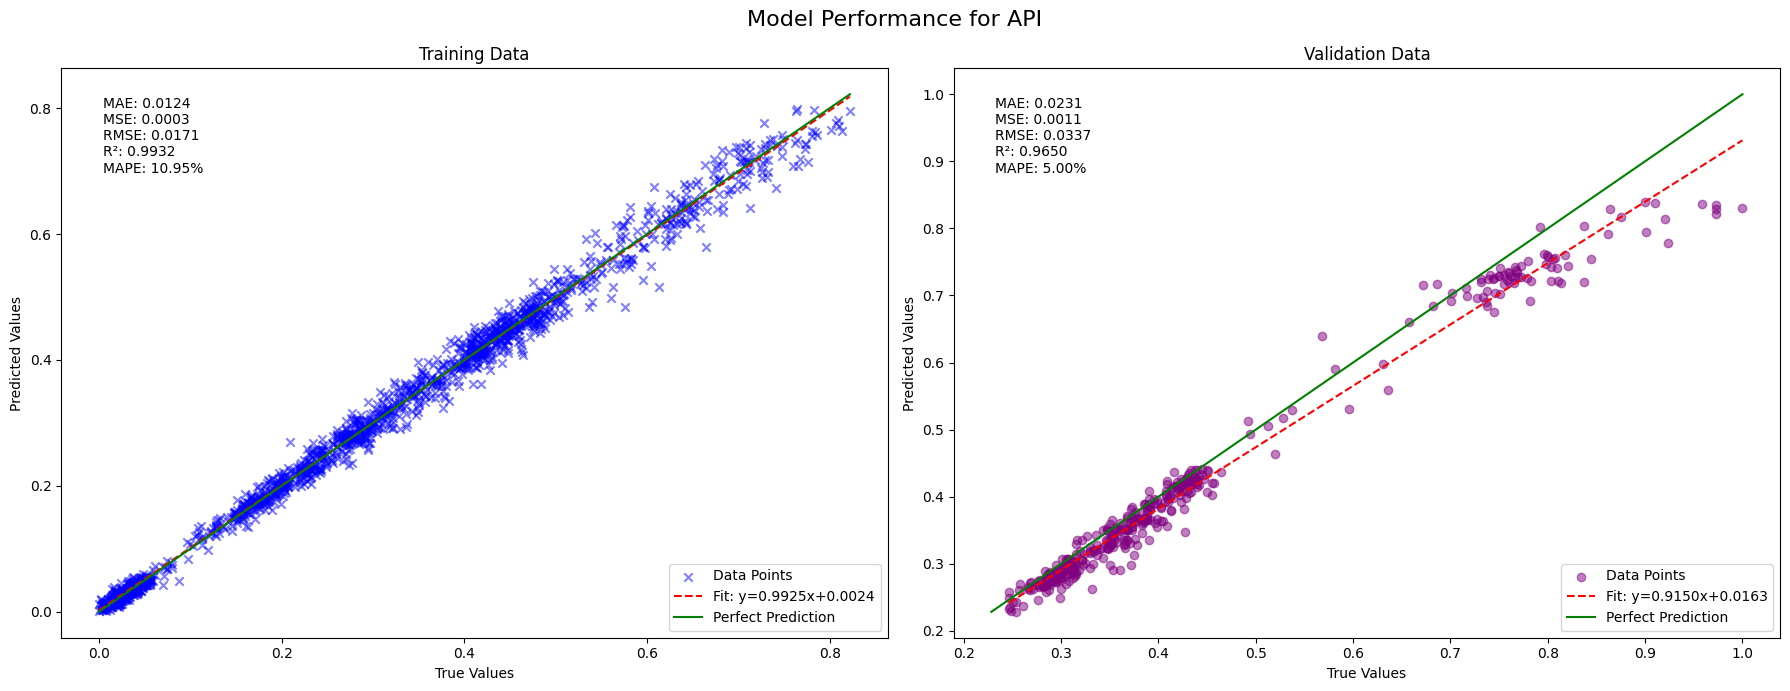


Calculating final metrics...
Technical correlations saved to results\API_technical_correlations.csv
Metrics saved to results\API_metrics.txt

Final Model Performance:

Training Metrics:
MAE: 0.0124
RMSE: 0.0171
MAPE: 10.95%

Validation Metrics:
MAE: 0.0231
RMSE: 0.0337
MAPE: 5.00%

Saving model components...
Model and scaler saved for symbol: API
Features list saved at model_components/api_features.pkl
Historical data saved at model_components/api_historical.npy
Last sequence saved at model_components/api_last_sequence.npy
Model components saved successfully.

Predicting future prices...


D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
D:\Model\venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid


Creating prediction visualization...
Plot saved as API_price_prediction.png


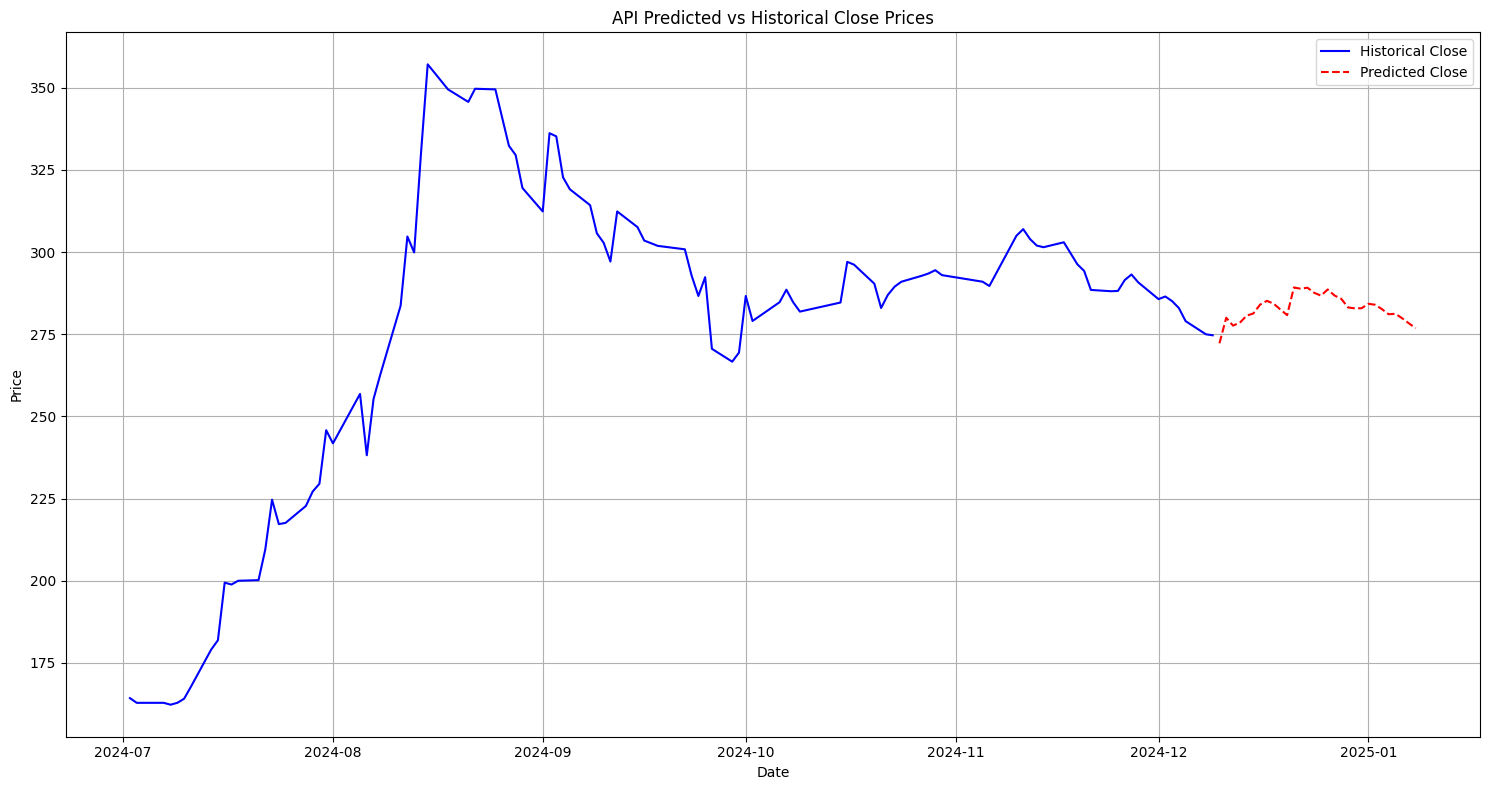

Predictions saved to results\API_predictions.csv

Process completed successfully!


In [23]:
if __name__ == "__main__":
    # Example usage:
    price_csv = "C:/Users/DELL/Desktop/For Students IOE/Merolagani Nepse Data/ALL STOCK CHARTS/Hydropower/API.csv"
    news_csv = "D:/StockSage/backend/API/sharesansar_news.csv"
    stock_symbol = "API"
    
    # Run the main function
    predictions = main(price_csv, news_csv, stock_symbol)